### Observation: Pairwise Scatter Plot Analysis

Pairwise scatter plots were created to investigate relationships
between bill length, bill depth, flipper length, and body mass.
Observations were colored by penguin species.

**Flipper Length and Body Mass:**
Gentoo penguins generally occupy higher flipper-length and
body-mass ranges. The overall positive relationship agrees
with the correlation coefficient of 0.87.

**Bill Length and Flipper Length:**
The species occupy partially different measurement ranges.
Combining these features may help distinguish penguin groups.

**Bill Depth and Body Mass:**
The species show different distributions across these features.
The negative correlation observed in the complete dataset
may partly reflect differences between species.

**Bill Length and Bill Depth:**
The scatter plots show differences in bill measurements
between species, although some overlap remains.

Overall, the scatter plots demonstrate that species-level
differences are important when interpreting relationships
between numerical measurements.

These plots show associations rather than causal relationships.
Further species-specific analysis would help determine
whether the observed relationships also hold within groups.

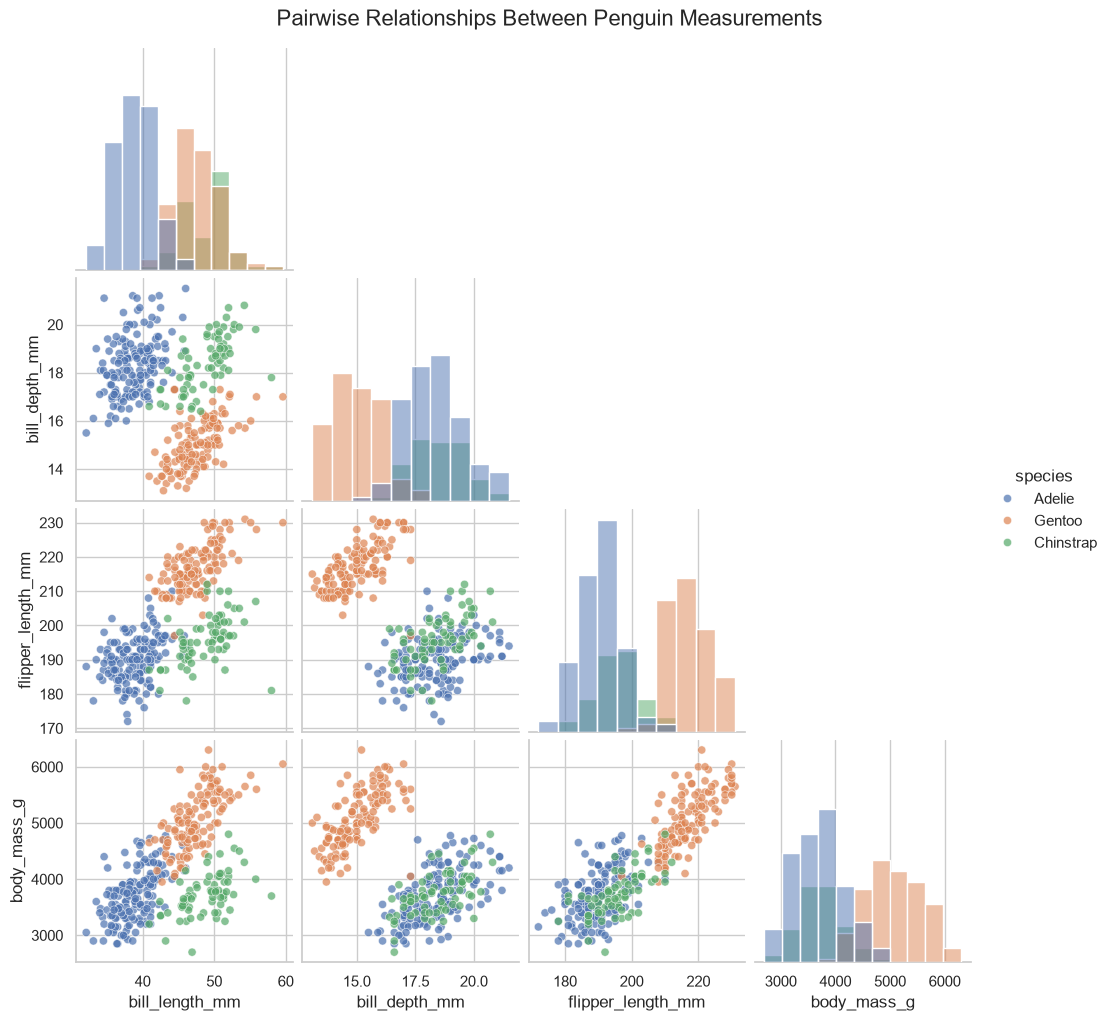

In [27]:
# Select the numerical features and species
pairplot_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
    "species"
]

pairplot_data = df_clean[pairplot_columns].copy()

# Create pairwise scatter plots, colored by species
pair_grid = sns.pairplot(
    pairplot_data,
    vars=[
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g"
    ],
    hue="species",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.7, "s": 35}
)

pair_grid.fig.suptitle(
    "Pairwise Relationships Between Penguin Measurements",
    y=1.02,
    fontsize=16
)

# Save the figure at high resolution
pair_grid.fig.savefig(
    VISUALIZATION_DIR / "pairwise_scatterplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation: Correlation Analysis

Pearson correlation coefficients were calculated to examine
linear relationships between the four numerical features.

**Flipper Length and Body Mass (r = 0.87):**
This is the strongest positive correlation. Penguins with
longer flippers tend to have greater body mass in this dataset.
Flipper length may be a useful feature for further body-mass
analysis.

**Bill Length and Flipper Length (r = 0.66):**
These features show a moderately strong positive relationship.

**Bill Length and Body Mass (r = 0.59):**
These features show a moderate positive relationship.

**Bill Depth and Flipper Length (r = -0.58):**
These features show a moderate negative relationship.

**Bill Depth and Body Mass (r = -0.47):**
These features show a moderate negative relationship.

**Bill Length and Bill Depth (r = -0.24):**
These features show a weak negative linear relationship.

Overall, flipper length and body mass have the strongest
linear association among the feature pairs examined.

These correlations describe the combined dataset and may
be influenced by differences between penguin species.
Correlation does not imply causation.

The analysis uses the numerical dataset after median
imputation. Imputation may influence the estimated
correlation coefficients.

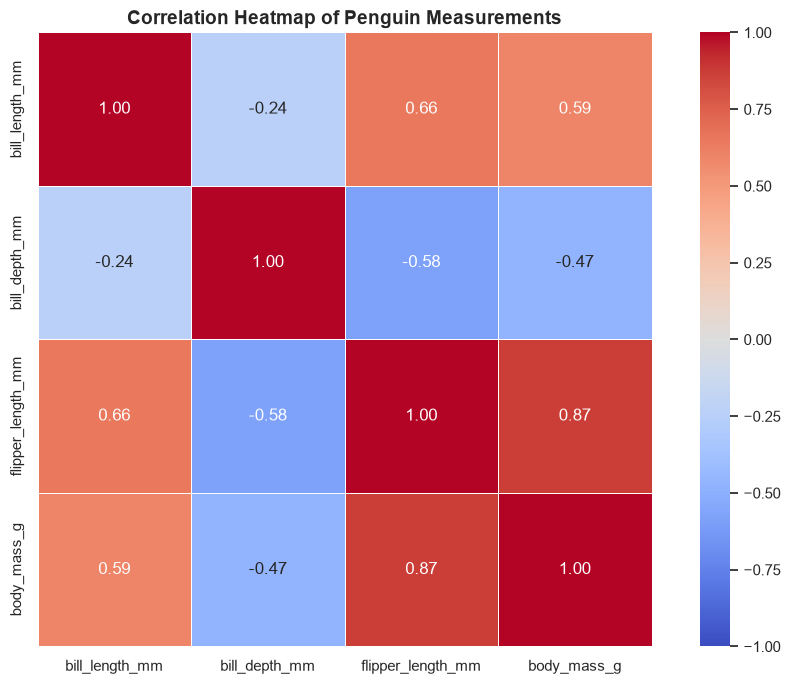

In [26]:
# Select numerical measurement columns
correlation_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Calculate Pearson correlation coefficients
correlation_matrix = df_clean[correlation_columns].corr()

# Plot the correlation heatmap
fig_corr, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)

ax.set_title(
    "Correlation Heatmap of Penguin Measurements",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# Save the visualization
fig_corr.savefig(
    VISUALIZATION_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation: Boxplot Analysis of Penguin Measurements

Boxplots were created to examine the median, interquartile range,
spread, and potential outliers of four numerical features.

**Bill Length:** The median is approximately 44 mm, with the
middle 50% of measurements concentrated between 39 mm and 48 mm.
The feature shows considerable variation.

**Bill Depth:** The median is approximately 17 mm. Its middle
50% lies between approximately 15.5 mm and 18.7 mm.

**Flipper Length:** The median is approximately 197 mm, and the
middle 50% of observations lies between approximately 190 mm
and 213 mm.

**Body Mass:** The median is approximately 4,000 g, with the
middle 50% of observations lying between approximately 3,550 g
and 4,750 g.

No individual outlier markers are visible in these plots.
This agrees with the earlier IQR analysis, which identified
zero potential outliers in the four numerical features.

The results describe the overall dataset. Further comparisons
by species may reveal differences that are hidden when all
penguins are analyzed together.

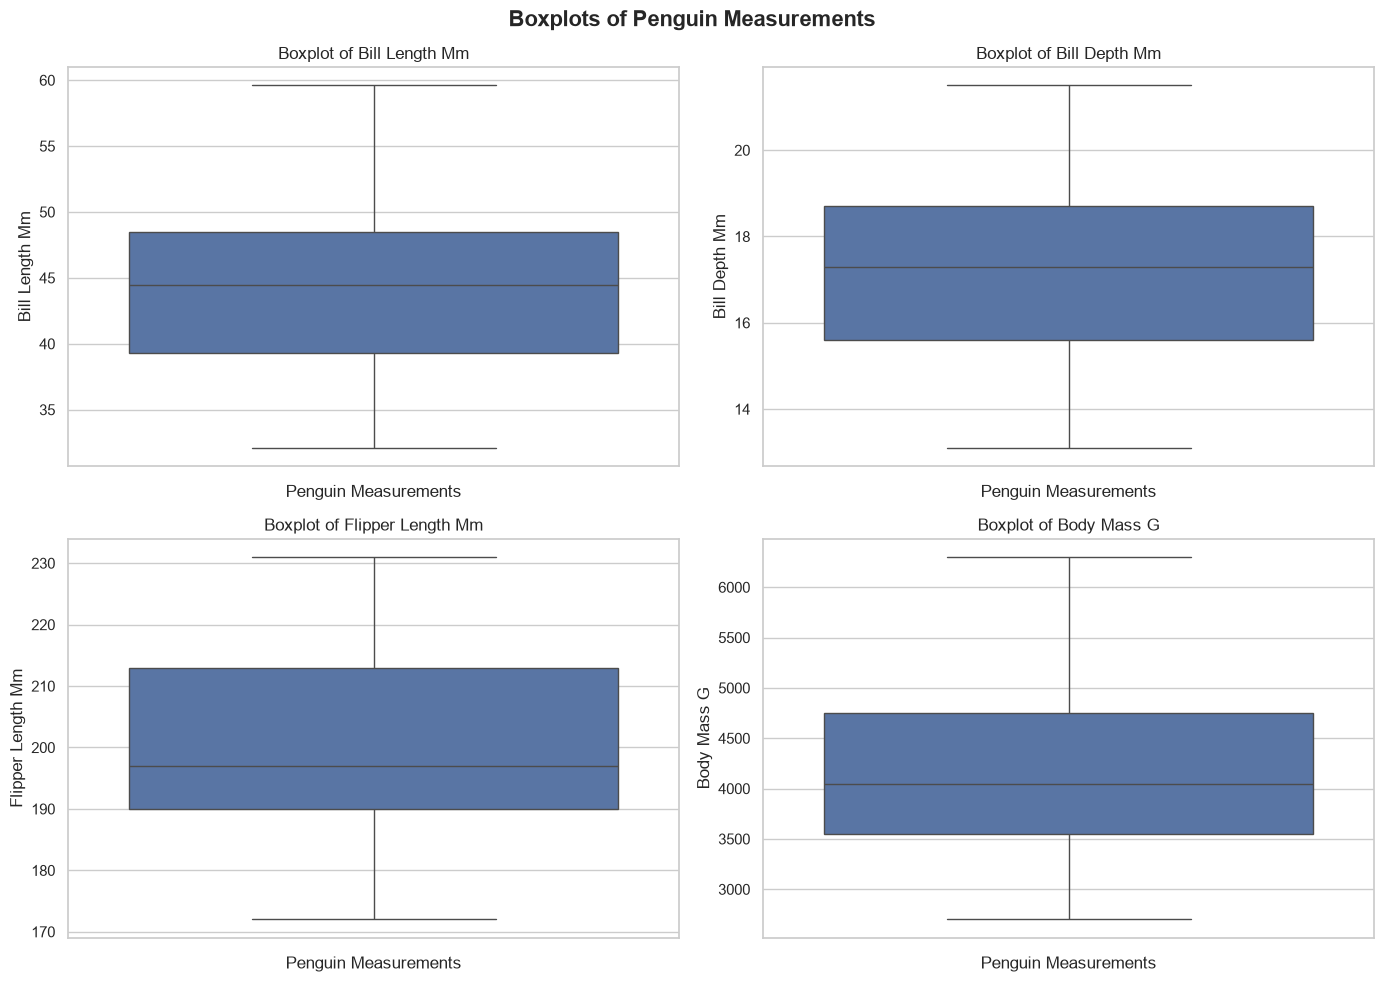

In [25]:
fig_box, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, ax in zip(measurement_columns, axes.flatten()):
    sns.boxplot(
        data=df_clean,
        y=column,
        ax=ax
    )

    ax.set_title(
        f"Boxplot of {column.replace('_', ' ').title()}"
    )
    ax.set_xlabel("Penguin Measurements")
    ax.set_ylabel(column.replace("_", " ").title())

plt.suptitle(
    "Boxplots of Penguin Measurements",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save the figure at high resolution
fig_box.savefig(
    VISUALIZATION_DIR / "measurement_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
from pathlib import Path

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

VISUALIZATION_DIR = PROJECT_DIR / "visualizations"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

output_path = VISUALIZATION_DIR / "feature_distributions.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved successfully:", output_path.exists())
print("File location:", output_path)

Saved successfully: True
File location: c:\Users\SIDDHARUDHA\OneDrive\Documents\EDA_Statistical_Visualization\visualizations\feature_distributions.png


### Observation: Distribution of Penguin Measurements

The histograms reveal differences in the distributions of the
four numerical measurement features.

**Bill Length:** The distribution shows multiple concentrations
of observations rather than a single, clearly symmetric peak.
This suggests that comparisons between penguin species may
provide additional insight.

**Bill Depth:** Most observations appear concentrated around
16–19 mm. The distribution is not perfectly symmetric, indicating
that the mean alone may not fully describe the measurements.

**Flipper Length:** The histogram shows concentrations around
185–195 mm and 210–220 mm. These patterns may reflect differences
between groups of penguins and warrant further investigation.

**Body Mass:** The distribution extends toward higher body masses
and appears right-skewed. This indicates variation in body mass
and motivates comparisons with flipper length and species.

These observations are descriptive and do not establish the
causes of the observed patterns. Species-level visualizations
and correlation analysis will be used to investigate the
relationships further.

The numerical measurements were median-imputed before plotting,
which may influence the distributions slightly.

### Observation: Feature Distributions

The histograms show the distributions of bill length, bill depth,
flipper length, and body mass.

The plots are used to assess the spread, concentration, skewness,
and possible multiple peaks in each feature.

Because the dataset contains multiple penguin species, some
measurements may show more than one concentration of observations.

These patterns can help guide further comparisons between species
and the interpretation of relationships between measurements.

The missing numerical values were median-imputed before plotting,
so the imputed observations should be considered when interpreting
the distributions.

In [23]:
from pathlib import Path

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

VISUALIZATION_DIR = PROJECT_DIR / "visualizations"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Save the current figure
fig.savefig(
    VISUALIZATION_DIR / "feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

print("Visualization saved successfully!")
print(VISUALIZATION_DIR / "feature_distributions.png")

Visualization saved successfully!
c:\Users\SIDDHARUDHA\OneDrive\Documents\EDA_Statistical_Visualization\visualizations\feature_distributions.png


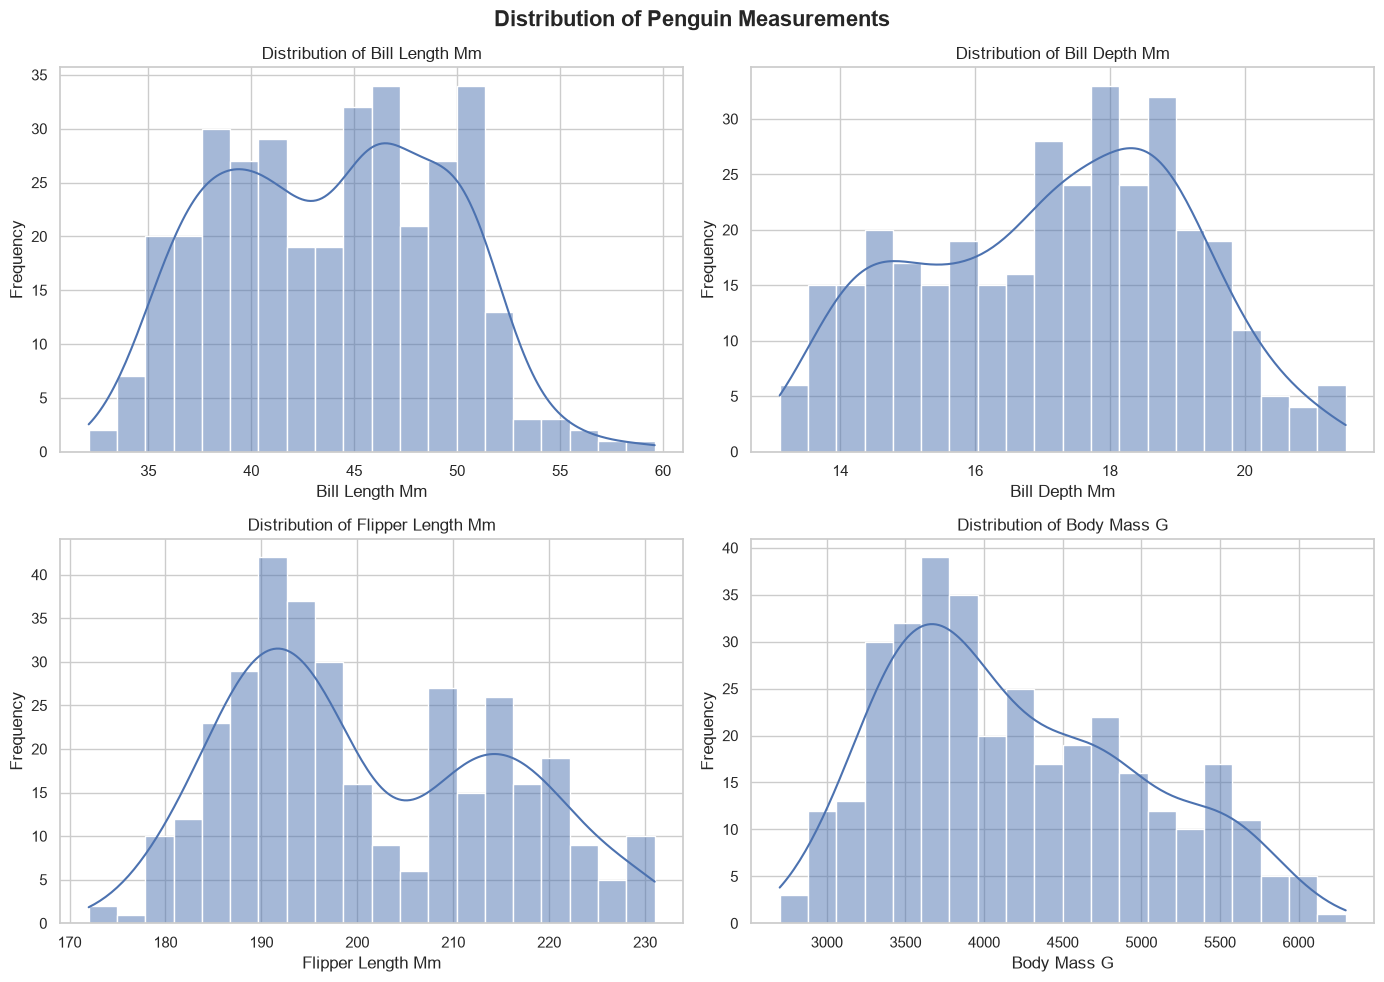

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual style
sns.set_theme(style="whitegrid")

# Create four feature distribution plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, ax in zip(measurement_columns, axes.flatten()):
    sns.histplot(
        data=df_clean,
        x=column,
        kde=True,
        bins=20,
        ax=ax
    )

    ax.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Distribution of Penguin Measurements",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Observation: Outlier Detection Using the IQR Method

The Interquartile Range (IQR) method was applied to four numerical
measurement features: bill length, bill depth, flipper length,
and body mass.

The IQR was calculated as Q3 - Q1. Potential outliers were defined
as values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR.

The analysis identified zero potential outliers in all four
features.

Therefore, no observations were removed or modified on the basis
of this outlier test.

This result applies to the dataset after median imputation.
The IQR method can miss unusual observations within individual
species, so subsequent visualizations will help assess the
distributions and relationships further.

In [21]:
# Detect outliers using the Interquartile Range (IQR) method

measurement_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

outlier_results = []

for column in measurement_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": column,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": int(outlier_count)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,bill_length_mm,39.28,48.5,9.23,25.44,62.34,0
1,bill_depth_mm,15.60,18.7,3.10,10.95,23.35,0
2,flipper_length_mm,190.00,213.0,23.00,155.50,247.50,0
3,body_mass_g,3550.00,4750.0,1200.00,1750.00,6550.00,0


### Observation: Missing Value Treatment

The original dataset contained 344 records and 8 columns.

Four numerical measurement columns contained missing values.
These were imputed using the median of their respective columns.

The median was selected because it is less sensitive to extreme
observations than the mean. This makes it a reasonable initial
imputation method for measurement data.

After numerical imputation, all four measurement columns contain
zero missing values. The remaining 11 missing values belong to
the categorical column `sex`.

These categorical values were retained as missing rather than
being replaced with an unsupported guess. No rows were deleted
during this stage.

Median imputation can affect the distribution and variance of
a feature, so this limitation will be considered when interpreting
the subsequent visualizations.

In [19]:
# Check missing values after numerical imputation
print("Missing values after numerical imputation:")

display(df_clean.isnull().sum())

print(
    "\nTotal missing values remaining:",
    df_clean.isnull().sum().sum()
)

Missing values after numerical imputation:


species               0
island                0
bill_length_mm        0
bill_depth_mm         0
flipper_length_mm     0
body_mass_g           0
sex                  11
year                  0
dtype: int64


Total missing values remaining: 11


In [18]:
# Fill missing numerical measurements using their column medians
for column in measurement_columns:
    median_value = df_clean[column].median()

    df_clean[column] = df_clean[column].fillna(median_value)

    print(f"{column}: median used = {median_value}")

bill_length_mm: median used = 44.45
bill_depth_mm: median used = 17.3
flipper_length_mm: median used = 197.0
body_mass_g: median used = 4050.0


In [17]:
# Select numerical measurement columns
measurement_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Display statistics before imputation
display(
    df_clean[measurement_columns].agg(
        ["count", "mean", "median", "std"]
    ).round(2)
)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
median,44.45,17.30,197.00,4050.00
std,5.46,1.97,14.06,801.95


In [16]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (344, 8)
Working dataset shape: (344, 8)


In [15]:
# Display rows containing at least one missing value
missing_rows = df[df.isnull().any(axis=1)]

print("Number of rows containing missing values:",
      len(missing_rows))

display(missing_rows)

Number of rows containing missing values: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


### Observation: Duplicate Detection

The dataset contains 344 records and 8 columns.

Exact duplicate detection identified 0 duplicate rows.
Therefore, no records were removed due to exact duplication.

Retaining all 344 records preserves the available observations
for subsequent data cleaning and statistical analysis.

In [13]:
display(df[df.duplicated(keep=False)])

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


In [14]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total rows before cleaning:", len(df))
print("Number of duplicate rows:", duplicate_count)

Total rows before cleaning: 344
Number of duplicate rows: 0


### Observation: Missing Value Analysis

The dataset contains 344 records and 8 columns.

The missing-value analysis shows that species, island, and year
have no missing values. Each of the four numerical measurement
columns contains 2 missing values (0.58%), while sex contains
11 missing values (3.20%).

The missing proportion is relatively small. However, the
appropriate treatment will depend on the affected records,
the distribution of each feature, and the analytical purpose.

Numerical missing values will be evaluated for median
imputation, while missing categorical values will be examined
separately to avoid introducing unsupported information.

In [10]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing percentages
missing_percentage = (df.isnull().mean() * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

display(missing_summary)

,Missing Values,Missing Percentage
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


In [9]:
display(df.describe(include='object'))

C:\Users\SIDDHARUDHA\AppData\Local\Temp\ipykernel_17660\1967400120.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


In [8]:
display(df.describe())

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [6]:
# Number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

Number of rows: 344
Number of columns: 8

Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


In [5]:
display(df.tail())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


In [4]:
display(df.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
from pathlib import Path
import pandas as pd

# Locate the project folder
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Locate the dataset
DATA_PATH = PROJECT_DIR / "data" / "penguins.csv"

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset location:", DATA_PATH)

Dataset loaded successfully!
Dataset location: c:\Users\SIDDHARUDHA\OneDrive\Documents\EDA_Statistical_Visualization\data\penguins.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

print("\nAll libraries are working!")

Pandas: 3.0.6
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2

All libraries are working!


In [1]:
import pandas as pd

print("Pandas version:", pd.__version__)
print("Pandas is working successfully!")

Pandas version: 3.0.6
Pandas is working successfully!
